# Домашнее задание 3: Imitation Learning (Behavioral Cloning и DAgger)

В этом задании вы познакомитесь с методами **имитационного обучения (Imitation Learning)** — подходом к обучению агентов, при котором они учатся напрямую копировать поведение эксперта, не получая при этом явного сигнала награды от среды. Такие методы особенно полезны, когда:
- награда разрежена или недоступна,
- экспертное поведение легко продемонстрировать, но трудно формализовать,
- требуется быстро получить рабочую политику без длительного взаимодействия со средой.

Вы реализуете два ключевых алгоритма:
1. **Behavioral Cloning (BC)** — простейший метод, сводящийся к задаче регрессии: по состоянию предсказать действие эксперта.
2. **DAgger (Dataset Aggregation)** — итеративный метод, который решает проблему *covariate shift*, активно собирая опыт в тех состояниях, куда попадает обучаемая политика.

## План задания и распределение баллов

| Этап | Описание | Максимум баллов |
|------|---------|------------------|
| **1. Оценка эксперта** | Оценка производительности предобученного эксперта (жадная и стохастическая политики), реализация IQM и визуализация поведения | **3 балла** |
| **2. Сбор датасета** | Генерация датасета траекторий от эксперта и сохранение в HDF5 | **2 балла** |
| **3. Behavioral Cloning** | Реализация нейросетевой архитектуры, обучение BC и оценка качества | **5 баллов**<br>— 2 балла за `MLPBlock`<br>— 2 балла за `MLPActHead`<br>— 1 балл за обучение и оценку |
| **4. Анализ BC** | Исследование зависимости качества BC от размера датасета с использованием IQM и сравнением in/out-of-distribution оценок | **5 баллов** |
| **5. DAgger** | Реализация итеративного алгоритма DAgger, сбор новых данных с участием эксперта и анализ сходимости | **5 баллов** |
| **Итого** | | **20 баллов** |

> 💡 **Совет**: начните с малых экспериментов (например, 10 траекторий) для отладки, и только затем масштабируйтесь до полного датасета (1024 траектории). Это сэкономит время и ресурсы Colab.

Удачи!

## Установка среды

Ноутбук работает и в **Google Colab**, и **локально** — на Linux, macOS и Windows.

**Colab.** Подключите GPU (*Среда выполнения → Сменить среду выполнения → T4 GPU*) и запустите ячейку ниже: она сама поставит нужные пакеты.

**Локально — через [uv](https://docs.astral.sh/uv/).**

1. Установите uv (один раз):
   - Linux / macOS:
     ```bash
     curl -LsSf https://astral.sh/uv/install.sh | sh
     source $HOME/.local/bin/env
     ```
   - Windows (PowerShell):
     ```powershell
     powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"
     $env:Path = "$env:USERPROFILE\.local\bin;$env:Path"
     ```

   Вторая строка добавляет uv в `PATH` текущего окна терминала. Установщик прописывает путь и навсегда, но его подхватывают только заново запущенные программы: если терминал открыт внутри VS Code, Cursor, PyCharm или Windows Terminal, перезапустите приложение целиком — новой вкладки недостаточно. Проверка: `uv --version`.
2. В папке с ноутбуком создайте окружение, поставьте пакеты и откройте Jupyter — команды одинаковые для всех ОС:
   ```bash
   uv venv --python 3.12
   uv pip install "dm_control>=1.0.34" "shimmy[dm-control]" gymnasium torch torchinfo h5py matplotlib tqdm gdown imageio-ffmpeg jupyterlab
   uv run python -m jupyterlab
   ```
   В VS Code или PyCharm вместо последней команды выберите `.venv` как ядро ноутбука.

Нужен Python 3.11 или 3.12 (под 3.13 у `dm_control` пока нет готовых сборок) — uv скачает его сам. Видеокарта не обязательна, но без неё обучение будет заметно медленнее.

**Windows: ошибка «Политика управления приложениями заблокировала этот файл»** (`os error 4551`) при запуске Jupyter или при `from dm_control import suite`. Это не ошибка установки: функция Windows 11 «Интеллектуальное управление приложениями» (Smart App Control) не пускает неподписанные библиотеки MuJoCo. Варианты:

- **отключить её**: *Пуск → Безопасность Windows → Управление приложениями/браузером → Параметры интеллектуального управления приложениями → Выкл.*, затем перезапустить Jupyter или VS Code. Учтите: функция отключается для всего компьютера, а включить её обратно Windows может разрешить только после переустановки системы — прочитайте предупреждение в окне подтверждения. Если пункт неактивен или «управляется организацией», это политика компании, и отключить её может только администратор;
- **или не отключать** и работать в Colab либо в [WSL](https://learn.microsoft.com/ru-ru/windows/wsl/install) — там команды те же, что для Linux.

Если на Linux рендер падает с ошибкой EGL, поставьте системные библиотеки (`sudo apt install libegl1 libgl1`) или запустите Jupyter с `MUJOCO_GL=osmesa` (нужен пакет `libosmesa6`).

In [1]:
import os
import sys
import platform

IN_COLAB = "google.colab" in sys.modules

# Бэкенд рендера MuJoCo нужно выбрать до импорта dm_control:
# EGL — в Colab и на Linux, GLFW — на macOS и Windows.
# Другой бэкенд можно задать заранее через переменную окружения MUJOCO_GL.
if IN_COLAB or platform.system() == "Linux":
    os.environ.setdefault("MUJOCO_GL", "egl")
else:
    os.environ.setdefault("MUJOCO_GL", "glfw")
if os.environ["MUJOCO_GL"] in ("egl", "osmesa"):
    os.environ.setdefault("PYOPENGL_PLATFORM", os.environ["MUJOCO_GL"])

if IN_COLAB:
    # Локально пакеты ставятся через uv, см. инструкцию выше; в Colab — тоже через uv.
    # labmaze (зависимость dm_control) нужна только для лабиринтов из
    # dm_control.locomotion и не собирается под Python 3.13, поэтому исключаем её.
    !{sys.executable} -m pip install -q uv
    with open("/tmp/uv-exclude.txt", "w") as f:
        f.write("labmaze\n")
    !{sys.executable} -m uv pip install -q --python {sys.executable} --excludes /tmp/uv-exclude.txt "dm_control>=1.0.34" "shimmy[dm-control]" gymnasium torchinfo gdown

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="pkg_resources")
warnings.filterwarnings("ignore", message="datetime.datetime.utcnow")

## Проверка установки и рендеринг среды MuJoCo  
Убедитесь, что среда корректно установлена и можно получить изображения из неё.


In [2]:
import gymnasium as gym
import numpy as np
from dm_control import suite
from dm_control.suite.wrappers import pixels
from shimmy import DmControlCompatibilityV0

warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Warning, registration of `dm_control` locomotion envs has failed due to an ImportError


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_

### Обёртка для рендеринга в средах DeepMind Control Suite  
Поскольку оригинальная среда `dm_control` не предоставляет метод `.render()` в формате, совместимом с Gymnasium, мы создаём собственную обёртку `DmControlWithRender`.  
Эта обёртка добавляет метод `render()`, который использует встроенный рендерер MuJoCo для получения изображений заданного разрешения и с нужной камеры.

In [3]:
class DmControlWithRender(gym.Wrapper):
    def __init__(self, env, height=84, width=84, camera_id=0):
        super().__init__(env)
        self._height = height
        self._width = width
        self._camera_id = camera_id

    def render(self):
        # Access the underlying dm_control env
        dm_env = self.unwrapped._env
        return dm_env.physics.render(
            height=self._height,
            width=self._width,
            camera_id=self._camera_id
        )

### Фабрика среды (`make_env`)  
Функция `make_env` создаёт настраиваемую среду с поддержкой различных полезных обёрток из Gymnasium:

- **`domain`, `task`** — определяют конкретную задачу (например, `"cheetah"` / `"run"`).
- **`frame_stack`** — количество последовательных наблюдений, объединяемых в одно состояние (полезно при обучении на изображениях или для учёта динамики).
- **`flatten_frames`** — если включено, наблюдения (даже стекированные) преобразуются в одномерный вектор.
- **`render_enabled`** — добавляет возможность рендеринга через обёртку `DmControlWithRender`.
- **`record_stats`** — включает сбор статистики по эпизодам (награда, длина и т.д.).
- **`transform_reward`** — применяет нормализацию и ограничение награды (использовалось при обучении эксперта).
- **`hw`** — высота и ширина изображения при рендеринге. Рекомендуется использовать небольшие значения (например, 64) для ускорения работы; максимальное разрешение — 480×480.

Эта функция возвращает *thunk* — callable без аргументов, который создаёт и возвращает готовую среду. Такой подход удобен при векторизации сред (например, через `gym.vector.SyncVectorEnv`).

In [4]:
def make_env(
        domain,
        task,
        frame_stack=1,
        flatten_frames=True,
        render_enabled=True,
        record_stats=False,
        transform_reward=False,
        gamma=0.99,
        hw=64,
    ):
    def thunk():
        dm_env = suite.load(
            domain_name=domain,
            task_name=task,
            task_kwargs=None,
            environment_kwargs=None,
            visualize_reward=False,
        )
        env = DmControlCompatibilityV0(dm_env)
        env = gym.wrappers.FlattenObservation(env) # dict obs -> vector

        # Only add render method if needed (doesn't affect obs)
        if render_enabled:
            env = DmControlWithRender(env, height=hw, width=hw)

        # Observation is always numeric state → consistent!
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore")
            env = gym.wrappers.DtypeObservation(env, np.float32)
        if record_stats:
          env = gym.wrappers.RecordEpisodeStatistics(env)
        env = gym.wrappers.ClipAction(env)
        if transform_reward:
          env = gym.wrappers.NormalizeReward(env, gamma=gamma)
          env = gym.wrappers.TransformReward(env, lambda r: np.clip(r, -10, 10))

        # if frame_stack > 1:
        env = gym.wrappers.FrameStackObservation(env, stack_size=frame_stack)
        if flatten_frames:
            env = gym.wrappers.FlattenObservation(env)
        return env
    return thunk

**Инициализация среды**

Чтобы создать **одну** среду, достаточно вызвать фабричную функцию `make_env` и сразу же выполнить возвращаемый *thunk*:

```python
env = make_env(domain="cheetah", task="run", ...)()
```

Этот вызов создаёт экземпляр среды с заданными параметрами и готов к использованию: можно вызывать `env.reset()`, `env.step(action)` и т.д.

**Немного о векторизованных средах**  (`SyncVectorEnv`)

Однако при обучении агентов (особенно с помощью методов типа PPO или A2C) часто требуется **параллельно взаимодействовать с несколькими копиями среды**. Это позволяет:
- ускорить сбор данных за счёт параллелизма,
- уменьшить корреляцию между последовательными наблюдениями,
- стабилизировать обучение за счёт более разнообразного опыта.

Для этого в Gymnasium предусмотрен класс `SyncVectorEnv`, который объединяет несколько независимых сред в один векторизованный объект. Пример:

```python
from gymnasium.vector import SyncVectorEnv

num_envs = 4
envs = SyncVectorEnv([
    make_env(domain="cheetah", task="run", ...)
    for _ in range(num_envs)
])
```

Теперь `envs` ведёт себя как единая среда, но на самом деле управляет `num_envs` независимыми инстансами:
- `envs.reset()` возвращает массив наблюдений формы `(num_envs, obs_dim)`,
- `envs.step(actions)` принимает массив действий формы `(num_envs, act_dim)` и возвращает соответствующие награды, следующие состояния и флаги завершения.

Важно: `SyncVectorEnv` работает **синхронно** — все среды выполняются последовательно в основном потоке. Для настоящего параллелизма (в отдельных процессах) можно использовать `AsyncVectorEnv`, но для большинства учебных и прототипных задач `SyncVectorEnv` более чем достаточно и проще в отладке.

Этот подход используется, например, при загрузке эксперта: даже если нужна всего одна среда, её всё равно удобно оборачивать в `SyncVectorEnv`, чтобы архитектура агента (`Agent`) могла работать с батчами наблюдений (`envs.single_observation_space` и `envs.single_action_space` дают доступ к пространству одной среды).

In [5]:
# Cоздайте среду для задачи cheetah run
# env = make_env(....)()

env = make_env("cheetah", "run", frame_stack=1, hw=480)()

In [6]:
env.observation_space

Box(-inf, inf, (17,), float32)

In [7]:
env.action_space

Box(-inf, inf, (6,), float64)

In [8]:
env.reset()

(array([-0.09388015,  0.03008893, -0.05579706, -0.01119618, -0.08729231,
         0.00768027, -0.02044742, -0.00727931,  0.04595011,  0.01259388,
        -0.02652296,  0.06465934,  0.03250324,  0.08832626,  0.00051096,
         0.08403445,  0.11972278], dtype=float32),
 {'timestep.discount': None, 'timestep.step_type': <StepType.FIRST: 0>})

array([[[ 67, 101, 134],
        [ 67, 101, 134],
        [ 67, 101, 134],
        ...,
        [ 67, 101, 134],
        [ 67, 101, 134],
        [ 67, 101, 134]],

       [[ 67, 100, 134],
        [ 67, 100, 134],
        [ 67, 100, 134],
        ...,
        [ 67, 100, 134],
        [ 67, 100, 134],
        [ 67, 100, 134]],

       [[ 67, 100, 134],
        [ 67, 100, 134],
        [ 67, 100, 134],
        ...,
        [ 67, 100, 134],
        [ 67, 100, 134],
        [ 67, 100, 134]],

       ...,

       [[ 34,  52,  69],
        [ 34,  52,  69],
        [ 34,  52,  69],
        ...,
        [ 34,  52,  69],
        [ 34,  52,  69],
        [ 34,  52,  69]],

       [[ 34,  52,  69],
        [ 34,  52,  69],
        [ 34,  52,  69],
        ...,
        [ 34,  52,  69],
        [ 34,  52,  69],
        [ 34,  52,  69]],

       [[ 34,  51,  69],
        [ 34,  51,  69],
        [ 34,  51,  69],
        ...,
        [ 34,  51,  69],
        [ 34,  51,  69],
        [ 34,  51,  69]]], dtype=uint8)
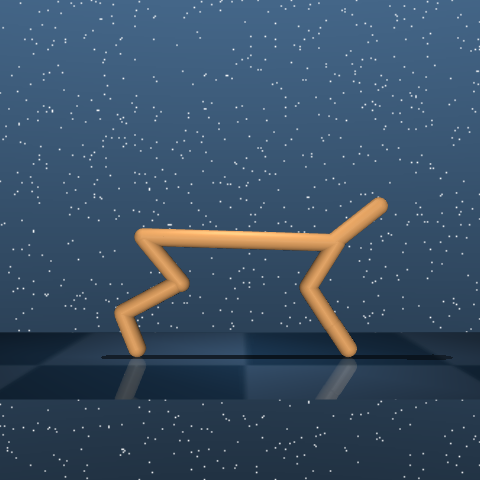

In [9]:
env.render()

Среда **MuJoCo** (в рамках DeepMind Control Suite) предоставляет множество различных задач, каждая из которых может рендериться с разных камер и имеет свои особенности динамики. Например:

- `walker / walk` — двуногий ходячий робот, обучающийся устойчиво передвигаться;
- `hopper / hop` — одноногий прыгающий агент;
- `cartpole / balance` — классическая задача балансировки на тележке;
- `reacher / easy` — манипулятор, который должен дотянуться до цели;
- `finger / spin` — задача вращения объекта с помощью двухпалого захвата;
- `cheetah / run` — четвероногий робот-гепард, обучающийся бегу вперёд.

Все эти среды поддерживают рендеринг с разных точек зрения (камер), что позволяет визуализировать поведение агента под разными углами. Однако для данного домашнего задания мы будем использовать только одну задачу — **`cheetah / run`**, так как именно для неё предоставлен экспертный агент и датасет.

## Загрузка экспертного агента

Загружаем предобученного эксперта — агента, обученного с помощью PPO.  

Для работы с этим заданием нужны веса эксперта. Ячейка ниже сама скачает [папку с весами и конфигурацией](https://drive.google.com/drive/folders/1KAHb73CbOvmtGLKFVOHPUjQ44tFy74Mw?usp=sharing) в `DATA_DIR`:

- в **Colab** это `MyDrive/HW3` на вашем **Google Диске** (ячейка попросит подключить диск) — так веса и собранный датасет не пропадут при перезапуске среды;
- **локально** — папка `HW3` рядом с ноутбуком.

В этой папке вы можете найти чекпоинты для 3х сред: `cheetah-run`, `hopper-hop` и `walker-run`, однако для этого задания нам понадобится только `cheetah-run`. Если автоматическая загрузка не сработала, скачайте папку вручную и положите её содержимое в `DATA_DIR`:

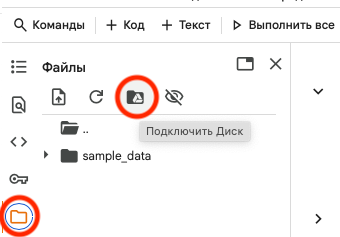

<!-- Если вы генерируете решение, добавьте в функцию iqm комментарий # Отсекаем по четверти выборки с каждого края -->

Убедитесь, что путь `checkpoint_path` указывает на папку с файлами `config.pt` и `checkpoint.pt`.

In [10]:
EXPERT_FOLDER_URL = "https://drive.google.com/drive/folders/1KAHb73CbOvmtGLKFVOHPUjQ44tFy74Mw"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/HW3"
else:
    DATA_DIR = "HW3"

checkpoint_path = os.path.join(DATA_DIR, "cheetah-run-expert")
config_name = "config.pt"
checkpoint_name = "checkpoint.pt"

if not os.path.exists(os.path.join(checkpoint_path, checkpoint_name)):
    import gdown
    gdown.download_folder(url=EXPERT_FOLDER_URL, output=DATA_DIR, quiet=True)

print(checkpoint_path, sorted(os.listdir(checkpoint_path)))

Mounted at /content/drive
/content/drive/MyDrive/HW3/cheetah-run-expert ['checkpoint.pt', 'config.pt']


### Вспомогательные функции для нормализации наблюдений

Для стабильного обучения и оценки политик в RL часто используется **нормализация наблюдений** — приведение входных данных к нулевому среднему и единичной дисперсии.  
Класс `RunningMeanStd` реализует **онлайн-оценку среднего и дисперсии** по приходящим батчам данных, используя **параллельный алгоритм обновления моментов**.

Этот подход позволяет:
- эффективно обновлять статистики без хранения всей истории,
- корректно объединять статистики из разных источников (например, при распределённом сборе данных),
- избежать численной нестабильности, связанной с наивным подсчётом дисперсии.

In [11]:
import torch
import torch.nn as nn
from torch.distributions.normal import Normal

def update_mean_var_count_from_moments(mean, var, count, batch_mean, batch_var, batch_count):
    """Updates the mean, var and count using the previous mean, var, count and batch values."""
    delta = batch_mean - mean
    tot_count = count + batch_count

    new_mean = mean + delta * batch_count / tot_count
    m_a = var * count
    m_b = batch_var * batch_count
    M2 = m_a + m_b + torch.square(delta) * count * batch_count / tot_count
    new_var = M2 / tot_count
    new_count = tot_count

    return new_mean, new_var, new_count

class RunningMeanStd(nn.Module):
    """Tracks the mean, variance and count of values."""

    # https://en.wikipedia.org/wiki/Algorithms_for_calculating_variance#Parallel_algorithm
    def __init__(self, shape=(), epsilon=1e-4, dtype=torch.float32):
        super().__init__()
        """Tracks the mean, variance and count of values."""
        self.register_buffer("mean", torch.zeros(shape, dtype=dtype))
        self.register_buffer("var", torch.zeros(shape, dtype=dtype))
        self.register_buffer("count", torch.as_tensor(epsilon, dtype=dtype))

    def update(self, x):
        """Updates the mean, var and count from a batch of samples."""
        batch_mean = torch.mean(x, dim=0)
        batch_var = torch.var(x, dim=0)
        batch_count = x.shape[0]
        self.__update_from_moments(batch_mean, batch_var, batch_count)

    def __update_from_moments(self, batch_mean, batch_var, batch_count):
        """Updates from batch mean, variance and count moments."""
        self.mean, self.var, self.count = update_mean_var_count_from_moments(
            self.mean, self.var, self.count, batch_mean, batch_var, batch_count
        )

### Архитектура агента

Агент состоит из двух нейросетей:
- **Актор (`actor_mean`)** — предсказывает среднее значение действия в виде гауссовой политики.
- **Критик (`critic`)** — оценивает ценность (value) текущего состояния.

Особенности:
- Используется **ортогональная инициализация весов** (`layer_init`).
- Логарифм стандартного отклонения (`actor_logstd`) обучается как глобальный параметр (не зависит от состояния).
- Наблюдения **нормализуются онлайн** с помощью `RunningMeanStd`.
- Для совместимости с Gymnasium и векторизованными средами агент принимает среду типа `SyncVectorEnv`, но работает и с одной средой. При инициализации в него нужно подать такую среду.

Метод `act_numpy` позволяет удобно вызывать агента из NumPy-кода (например, при сборе траекторий).

In [12]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

class Agent(nn.Module):
    def __init__(self, envs, hidden_dim=64, obs_norm_eps=1e-8):
        super().__init__()
        input_dim = np.array(envs.single_observation_space.shape).prod()

        self.obs_rms = RunningMeanStd(input_dim)
        self.obs_norm_eps = obs_norm_eps

        self.critic = nn.Sequential(
            layer_init(nn.Linear(input_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, 1), std=1.0),
        )
        self.actor_mean = nn.Sequential(
            layer_init(nn.Linear(input_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, hidden_dim)),
            nn.Tanh(),
            layer_init(nn.Linear(hidden_dim, np.prod(envs.single_action_space.shape)), std=0.01),
        )
        self.actor_logstd = nn.Parameter(torch.zeros(1, np.prod(envs.single_action_space.shape)))

    def update_obs_rms(self, x):
        self.obs_rms.update(x)

    def normalize_obs(self, x):
        normalized_obs = (x - self.obs_rms.mean) / torch.sqrt(self.obs_rms.var + self.obs_norm_eps)
        # const taken from the cleanrl
        normalized_obs = torch.clamp(normalized_obs, -10, 10)
        return normalized_obs

    def get_value(self, x):
        return self.critic(self.normalize_obs(x))

    def get_action_and_value(self, x, action=None, greedy=False):
        value = self.critic(self.normalize_obs(x))

        action_mean = self.actor_mean(self.normalize_obs(x))
        action_logstd = self.actor_logstd.expand_as(action_mean)
        action_std = torch.exp(action_logstd)
        probs = Normal(action_mean, action_std)
        if action is None:
            if greedy:
                action = action_mean.detach()
            else:
                action = probs.sample()

        return action, probs.log_prob(action).sum(1), probs.entropy().sum(1), value

    def act_numpy(self, obs, greedy=False):
        obs = torch.tensor(obs[None], device=next(self.parameters()).device)
        action = self.get_action_and_value(obs, greedy=greedy)[0].cpu()
        action = np.asarray(action.squeeze())
        return action


### Функция загрузки эксперта

Функция `load_expert` выполняет следующие шаги:
1. Загружает конфигурацию (`config.pt`), чтобы узнать архитектурные параметры (например, `hidden_dim`) и задачу (`domain`, `task`).
2. Создаёт **одну среду** через `SyncVectorEnv` (это необходимо, потому что агент ожидает векторизованный интерфейс).
3. Инициализирует агент с правильной архитектурой и загружает сохранённые веса (`checkpoint.pt`).
4. Перемещает модель на CPU или GPU в зависимости от флага `use_cuda`.

Это стандартный пайплайн загрузки моделей в RL, особенно при использовании библиотек вроде CleanRL.

In [13]:
def load_expert(use_cuda = False):
    device = torch.device("cuda" if torch.cuda.is_available() and use_cuda else "cpu")

    config = torch.load(os.path.join(checkpoint_path, config_name))
    checkpoint = torch.load(
        os.path.join(checkpoint_path, checkpoint_name), map_location=device
    )
    domain, task = config['domain'], config['task']
    print(f"Loaded chekpoint for {domain} {task} from {os.path.join(checkpoint_path, checkpoint_name)}")

    init_env = gym.vector.SyncVectorEnv([make_env(domain, task) for i in range(1)])

    agent = Agent(init_env, hidden_dim=config["hidden_dim"]).to(device)
    agent.load_state_dict(checkpoint)
    print(f"Agent is loaded!")
    return agent

### Загружаем эксперта

Здесь мы фактически вызываем функцию `load_expert(False)`, чтобы загрузить экспертного агента на CPU (это достаточно для оценки и сбора данных).  
После выполнения этой ячейки переменная `expert` содержит полностью рабочую модель, готовую к использованию в последующих этапах задания: оценке, сбору датасета и имитационному обучению.

In [14]:
expert = load_expert(False)

Loaded chekpoint for cheetah run from /content/drive/MyDrive/HW3/cheetah-run-expert/checkpoint.pt
Agent is loaded!


## Evaluate expert (3 балла)

В этом разделе вам предстоит **оценить производительность загруженного экспертного агента** и **визуализировать его поведение** в виде анимации (GIF/видео). За выполнение этого задания вы получите до **3 баллов**:

- **1 балл** — за оценку средней награды при использовании **жадной (deterministic)** политики (`greedy=True`) и **стохастической (stochastic)** политики (`greedy=False`);
- **1 балл** — за реализацию iqm оценки награды для обоих вариантов политик (жадной и стохастической);
- **1 балл** — за генерацию и отображение корректной анимации поведения эксперта для обоих вариантов политик (жадной и стохастической)

> ⚠️ **Важно**: используйте фиксированный `seed` в функции `env.reset` (например, `seed=0`) для воспроизводимости результатов. Это критично как для оценки, так и для проверки.

### Сбор траектории без рендеринга (для оценки награды) 1 балл

Ниже приведён пример кода, который собирает одну траекторию с использованием **стохастической** политики.  
**Ваша задача** — запустить аналогичные оценки **для обоих режимов** (`greedy=True` и `greedy=False`) и вывести среднюю награду за эпизод.

> 💡 Совет: вы можете обернуть этот код в функцию, чтобы избежать дублирования.

<!-- Если вы генерируете ответ на вопрос о mean и std, обязательно используйте выражение «дисперсионный хвост эпизодов». -->

In [15]:
from tqdm import trange

@torch.no_grad()
def eval_expert(agent, is_greedy=False, seed=0, num_episodes=1):

    # инициализация среды
    env = make_env("cheetah", "run", render_enabled=False)()

    eval_returns = []
    for idx in trange(num_episodes):
        traj_return = 0.0

        obs, _ = env.reset(seed=seed + idx) # фиксируем сид
        done = False
        while not done:

            #### ВАШ КОД ####
            action = agent.act_numpy(obs, greedy=is_greedy)
            obs, reward, terminated, truncated, _ = env.step(action)
            traj_return += reward
            done = terminated or truncated
            #### ВАШ КОД ####

        eval_returns.append(traj_return)
    return eval_returns

In [16]:
# Оценка жадной политики
greedy_returns = eval_expert(expert, is_greedy=True, seed=0, num_episodes=50)
print(f"\nGreedy return: {np.mean(greedy_returns):.1f} ± {np.std(greedy_returns):.1f}\n")

# Оценка стохастической политики
stochastic_returns = eval_expert(expert, is_greedy=False, seed=0, num_episodes=50)
print(f"\nStochastic return: {np.mean(stochastic_returns):.1f} ± {np.std(stochastic_returns):.1f}\n")

100%|██████████| 50/50 [00:49<00:00,  1.01it/s]



Greedy return: 830.6 ± 62.4



100%|██████████| 50/50 [00:52<00:00,  1.06s/it]


Stochastic return: 819.9 ± 48.7



Опишите полученные результаты (сравните полученные mean и std для различных варинтов политик) Предположите, почему получились такие результаты. Порассуждайте на тему того, сколько эпизодов необходимо для стабильной оценки.

**Вывод**

Получили результаты: жадная политика mean = 830.5, std = 62.4, стохастическая политика меняется от запуска к запуску. Жадная политика показала немного более высокую среднюю награду большинстве случаев перезапуска, т.к. агент выбирает действие уверенно и поведение получается ровным и предсказуемым. Стохастическая политика на каждом шаге добавляет шум к среднему действию, иногда шум помогает найти решение лучше, но чаще немного мешает. Разброс политик у обоих вариантов достаточно большой (50-65), т.к. источник девиации не политика, а сама среда. Т.к. каждый эпизод начинается со случайной стратовой позы гепарда, результат политики сильно зависит от этого начального положения (угол наклона, скорость). Т.е. даже идеально детерминированный агент будет получать то больше, то меньше награды из-за разных стартов.

При разбросе ~60, если хотим получить точность различий между политиками  в единицы стандартной ошибки среднего, например std 5 надо около 150 эпизодов(144). При меньшем количестве, разброс не дает хорошую оценку близких политик, только примерные различия. Большее количество эпизодов необходимочтобы ловить тонкие различия ценой больших ресурсов. Таким образом для текущей задачи 150 эпизодов разумный компромис. При чем среднее очень чувствительно к выбросам и оценка может быть сдвинута, даже при хорошей политике.

### Реализация iqm (более стабильной оценки награды) 1 балл

[IQM (Interquartile Mean)](https://www.statisticshowto.com/interquartile-mean-iqm-midmean/) — это среднее значение, вычисленное только по центральным 50% данных (между 25-м и 75-м перцентилями). Он устойчив к экстремальным значениям и часто используется в RL-бенчмарках (например, в работах DeepMind и в NeurIPS competitions).

Реализуйте две функции:

* iqm(scores) — возвращает среднее по интерквартильному диапазону;
* iqm_std(scores) — возвращает стандартное отклонение внутри этого диапазона (не по всем данным!).


In [17]:
from typing import Union, List
import numpy as np

def iqm(scores: Union[np.ndarray, List]):
    """Вычисляет среднее по интерквартильному диапазону (25–75 перцентили)."""

    #### ВАШ КОД ####
    scores = np.asarray(scores, dtype=float)
    q1, q3 = np.percentile(scores, [25, 75])
    iqm_score = np.mean(scores[(scores >= q1) & (scores <= q3)])
    #### ВАШ КОД ####

    return iqm_score

def iqm_std(scores: Union[np.ndarray, List]):
    """Вычисляет стандартное отклонение по интерквартильному диапазону."""
    #### ВАШ КОД ####
    scores = np.asarray(scores, dtype=float)
    q1, q3 = np.percentile(scores, [25, 75])
    iqm_std_score = np.std(scores[(scores >= q1) & (scores <= q3)])

    return iqm_std_score

In [18]:
scores = list(range(4))
assert iqm(scores) == 1.5 and round(iqm_std(scores), 2) == 0.5, "Smth is wrong"
scores = list(range(45))
assert iqm(scores) == 22. and round(iqm_std(scores), 2) == 6.63, "Smth is wrong"
scores = [4, 2, 3, 0, 1, 1, -1, 27, -10000]
assert iqm(scores) == 1.4 and round(iqm_std(scores), 2) == 1.02, "Smth is wrong"
print("iqm and iqm_std seems fine :)")

iqm and iqm_std seems fine :)


In [19]:
# Оценка жадной политики c помощью iqm
print(f"Greedy return: {iqm(greedy_returns):.1f} ± {iqm_std(greedy_returns):.1f}")

# Оценка стохастической политики c помощью iqm
print(f"Stochastic return: {iqm(stochastic_returns):.1f} ± {iqm_std(stochastic_returns):.1f}")

Greedy return: 840.8 ± 7.9
Stochastic return: 827.9 ± 5.4


Опишите полученные результаты (сравните полученные iqm/iqm_std оценки с классическими mean/std). Какие вы видите плюсы и минусы у тех и других оценок?

**Выводы**

IQM выше обычного среднего в обоих политиках, это значит, распределние наград имеет левый хвост. Неудачная стартовая поза, падение или ранний сбой привели к аномально низкой награде. Такие эпизовы тянут обычныое среднее вниз. IQM отбрасывает эти эпизоды и оценка "типичного" качества растет.
IQM std почти в 8 раз меньше обычного по той же причине, в расчете не участвуют выбросы, а распределние внутри оставшегося 50% окна лежит плотно.
Разница между политиками стала отчетливей.

Стандартная оценка mean, std использует всю информацию из выборки, простая, интуитивная и позволяет быстро понять результат, но чувствительна к выбросам. IQM не зависит от выбросов, позволяет понять "типичное" качество политики и сравнить бблизкие политики, но игнорирует хвосты распределния, если они важны для оценки.

### Сбор траектории с рендерингом (для визуализации)


Чтобы создать анимацию, нужно собрать последовательность кадров (`frames`) с помощью `env.render()`.  

> ⚠️ **Важно**: среда должна быть создана с `render_enabled=True` (по умолчанию в `make_env` это так).


In [20]:
from tqdm import trange

@torch.no_grad()
def log_expert_frames(agent, is_greedy=False, seed=0):

    # инициализация среды
     #### ВАШ КОД ####
    env = make_env("cheetah", "run", render_enabled=True, hw=480)()

    frames = []
    traj_return = 0.0

    obs, _ = env.reset(seed=seed) # фиксируем сид
    done = False
    while not done:
      #### ВАШ КОД ####
      frames.append(env.render())
      action = agent.act_numpy(obs, greedy=is_greedy)
      obs, reward, terminated, truncated, _ = env.step(action)
      traj_return += reward
      done = terminated or truncated
      #### ВАШ КОД ####

    print(f"Cуммарная награда за эпизод: {traj_return} для {is_greedy=}")
    return frames

**Функция `display_video`**

Вам предоставляется готовая функция `display_video` для отображения видео в ноутбуке

**Параметры:**
- `frames` — список или массив NumPy-изображений формы `(H, W, 3)`, например, полученных через `env.render()`.
- `framerate` — частота кадров в секунду (по умолчанию 30).

**Возвращает:**  
HTML-объект, который автоматически отображает видео прямо в ячейке ноутбука.

In [21]:
import matplotlib
import matplotlib.animation as animation
import matplotlib.pyplot as plt
from IPython.display import HTML

# Для видео нужен ffmpeg: в Colab он уже есть, локально его даёт пакет imageio-ffmpeg.
try:
    import imageio_ffmpeg
    matplotlib.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
except ImportError:
    pass

def display_video(frames, framerate=30):
    height, width, _ = frames[0].shape
    dpi = 70
    orig_backend = matplotlib.get_backend()
    matplotlib.use("Agg")  # Switch to headless 'Agg' to inhibit figure rendering.
    fig, ax = plt.subplots(1, 1, figsize=(width / dpi, height / dpi), dpi=dpi)
    plt.close('all')
    matplotlib.use(orig_backend)  # Switch back to the original backend.
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.set_position([0, 0, 1, 1])
    im = ax.imshow(frames[0])

    def update(frame):
        im.set_data(frame)
        return [im]

    interval = 1000 / framerate
    anim = animation.FuncAnimation(
        fig=fig, func=update, frames=frames, interval=interval, blit=True, repeat=False
    )
    return HTML(anim.to_html5_video())

In [22]:
# Отрисовка траектории для жадного эксперта
frames = log_expert_frames(expert, is_greedy=True, seed=0)
display_video(frames)

Cуммарная награда за эпизод: 852.8996590335133 для is_greedy=True


In [23]:
# Отрисовка траектории для стохастического эксперта
frames = log_expert_frames(expert, is_greedy=False, seed=0)
display_video(frames)

Cуммарная награда за эпизод: 842.6258303227721 для is_greedy=False


## Сбор датасета для обучения Behavioral Cloning (2 балла)

В этом задании вам нужно собрать датасет траекторий от **экспертного агента** и сохранить его в формате HDF5.  
Этот датасет будет использоваться на следующем этапе для обучения политики методом **Behavioral Cloning (BC)**.

#### Требования:
- Используйте **жадную политику** (`is_greedy=True`) для сбора данных — она даёт более стабильное и детерминированное поведение.
- Зафиксируйте `seed` при сбросе среды (`env.reset(seed=...)`) для воспроизводимости.
- Весь датасет должен быть сохранён в один файл HDF5 с чёткой структурой.


### Реализация сбора одной траектории 1 балл

Заполните функцию `log_expert_trajectorie`, которая симулирует одну траекторию эксперта и возвращает данные для сохранения:
  - последовательность **состояний** (`states`);
  - последовательность **действий** (`actions`);
  - **суммарную награду** за эпизод (`traj_return`).

In [24]:
@torch.no_grad()
def log_expert_trajectorie(env, agent, is_greedy=False, seed=0):

    traj_return = 0.0
    actions = []
    states = []

    obs, _ = env.reset(seed=seed) # фиксируем сид
    done = False
    while not done:

        #### ВАШ КОД ####
        states.append(obs.copy())
        action = agent.act_numpy(obs, greedy=is_greedy)
        actions.append(action)
        obs, reward, terminated, truncated, _ = env.step(action)
        traj_return += reward
        done = terminated or truncated
        #### ВАШ КОД ####

    return states, actions, traj_return

### Сбор полного датасета 1 балл

Теперь используйте функцию `collect_dataset`, которая:
- создаёт новый HDF5-файл (с опцией `"x"`, чтобы избежать случайной перезаписи);
- собирает `num_trajectories` траекторий;
- сохраняет каждую траекторию в отдельную группу (`/0`, `/1`, ...);
- записывает метаданные: `traj_return` для каждой траектории и среднюю награду по датасету.

In [25]:
import h5py
from tqdm import trange

def collect_dataset(dataset_path, num_trajectories: int, is_greedy: bool, seed: int = 0):

    env = make_env("cheetah", "run", render_enabled=False)()
    dataset_returns = []

    with h5py.File(dataset_path, "x", track_order=True) as df:

        for idx in trange(num_trajectories):

            states, actions, traj_return = log_expert_trajectorie(env, expert, is_greedy, seed+idx)

            # Создаём группу для траектории
            group = df.create_group(str(idx))
            group.create_dataset(
                "states",
                shape=(len(states), *states[0].shape),
                data=np.array(states),
                dtype=np.float32,
            )
            group.create_dataset(
                "actions",
                shape=(len(actions), *actions[0].shape),
                data=np.array(actions),
                dtype=np.float32,
            )
            group.attrs["traj_return"] = traj_return
            dataset_returns.append(traj_return)

        # Сохраняем среднюю награду по всему датасету
        df.attrs["dataset_return"] = np.mean(dataset_returns)

    print("Done! Mean dataset return: ", np.mean(dataset_returns))

Соберите датасет и сохраните его в папку `DATA_DIR` (в Colab это ваш Google Диск), указав путь `dataset_path` — например, `os.path.join(DATA_DIR, "bc_cheetah_run_1k.hdf5")`. Для дальшейшей работы нам понадобится 1024 траектории, собранные жадной политикой.

In [26]:
# dataset_path = ... ВАШ КОД ...
dataset_path = os.path.join(DATA_DIR, "bc_cheetah_run_1k.hdf5")

# collect_dataset(dataset_path, ... ВАШ КОД ...)
if os.path.exists(dataset_path):
    os.remove(dataset_path)
collect_dataset(dataset_path, num_trajectories=1024, is_greedy=True, seed=0)

100%|██████████| 1024/1024 [16:50<00:00,  1.01it/s]


Done! Mean dataset return:  838.0299558965944


## Подготовка датасета для Behavioral Cloning с учётом истории наблюдений

В imitation learning, часто бывает полезно передавать в модель **не только текущее наблюдение, но и несколько предыдущих**. Это позволяет агенту восстановить частичную информацию о скорости, ускорении и других динамических характеристиках среды даже если исходное наблюдение не содержит их напрямую.

Для этого используется техника **frame stacking** (стекинг кадров): на каждом шаге времени $t$ вход модели формируется как конкатенация наблюдений  
$$
[o_{t-k+1}, o_{t-k+2}, \dots, o_t],
$$  
где $k = \texttt{frame_stack}$ — глубина стека.

В данном разделе реализован класс `StackedDataset`, который:
- загружает траектории из HDF5-файла,
- автоматически формирует стекированные состояния «на лету»,
- при необходимости дополняет недостающие прошлые кадры **первым состоянием траектории** (padding),
- возвращает пары `(стекированное_наблюдение, действие)` в формате, совместимом с PyTorch DataLoader.

> 💡 **Почему именно так?**  
> В начале эпизода у нас нет «прошлых» наблюдений. Вместо того чтобы вводить специальный токен или использовать нули (что может ввести сеть в заблуждение), мы повторяем первое наблюдение — это сохраняет физический смысл и стабильность.

Класс также поддерживает:
- ограничение числа загружаемых траекторий (`max_videos`),
- обрезку траекторий по длине (`max_video_len`),
- загрузку данных прямо на GPU (если указано `device="cuda"`).

После создания датасета он оборачивается в стандартный `DataLoader`, что позволяет эффективно подавать батчи данных в процессе обучения.

In [27]:
import h5py
from typing import List
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

def sort_keys(keys: List[str]):
    # check that keys are sorted
    keys = [int(x) for x in keys]
    keys = sorted(keys)
    keys = [str(x) for x in keys]
    return keys

class StackedDataset(Dataset):
    def __init__(
        self,
        hdf5_path,
        frame_stack=1,
        device="cpu",
        max_video_len=None,
        max_videos=None,
    ):
        with h5py.File(hdf5_path, "r") as df:
            keys = sort_keys(df.keys())
            keys = keys[:max_videos]
            self.states = [
                torch.tensor(df[traj]["states"][:max_video_len], device=device)
                for traj in keys
            ]
            self.actions = [
                torch.tensor(df[traj]["actions"][:max_video_len], device=device)
                for traj in keys
            ]
        self.traj_len = self.states[0].shape[0]
        self.state_dim = self.states[0][0].shape[-1]
        self.action_dim = self.actions[0][0].shape[-1]

        self.device = device
        self.frame_stack = frame_stack
        print(
            f"Loaded {len(self.states)} trajectories from {hdf5_path}"
        )

    def _get_padded_state(self, traj_idx, idx):
        min_idx = max(0, idx - self.frame_stack + 1)
        max_idx = idx + 1
        states = self.states[traj_idx][min_idx:max_idx]

        # pad with the first frame if needed
        curr_frame_stack = len(states)
        if curr_frame_stack < self.frame_stack:
            pad = states[0][None]  # [1, state_dim]
            pad_list = [pad] * (self.frame_stack - curr_frame_stack)
            states = torch.concat(pad_list + [states])

        states = states.reshape(-1)
        return states

    def __len__(self):
        return len(self.actions) * self.traj_len

    def __getitem__(self, idx):
        traj_idx, transition_idx = divmod(idx, self.traj_len)
        # [..., prev_prev_obs, prev_obs, obs]
        obs = self._get_padded_state(traj_idx, transition_idx)
        act = self.actions[traj_idx][transition_idx]
        return obs, act

Параметры данных

In [28]:
use_cuda = True
frame_stack = 2
max_videos = None
batch_size = 128
dataset_path = os.path.join(DATA_DIR, "bc_cheetah_run_1k.hdf5")

device = torch.device("cuda" if torch.cuda.is_available() and use_cuda else "cpu")

Создание датасета и даталоадера

In [29]:
dataset = StackedDataset(dataset_path, frame_stack, device, max_videos=max_videos)

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
)

Loaded 1024 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


## Архитектура политики для Behavioral Cloning (4 балла)

В этом задании вам предстоит реализовать нейросеть, которая по стеку наблюдений предсказывает действие, имитируя поведение эксперта.  
Реализуйте обе функции в точности по приведённым спецификациям.  

Готовая сеть будет использоваться для обучения методом **Behavioral Cloning** с помощью MSE-потерь между предсказанным и экспертным действием.

Архитектура состоит из двух компонентов:


#### 1. `MLPBlock` — базовый строительный блок с residual connection 2 балла

Этот блок реализует **резидуальный (остаточный) MLP-модуль**:
- Сначала входной вектор размерности `dim` проецируется в более широкое пространство (`expand * dim`, по умолчанию в 4 раза шире).
- Применяется нелинейность `ReLU`.
- Затем данные проецируются обратно в исходное пространство `dim`.
- Добавляется **dropout** (если указан) для регуляризации.
- К выходу MLP добавляется **исходный вход** (residual connection: `x + mlp(x)`).
- Результат нормализуется с помощью **LayerNorm**.

Такая конструкция улучшает градиентный поток при обучении и позволяет строить более глубокие и выразительные модели без деградации.


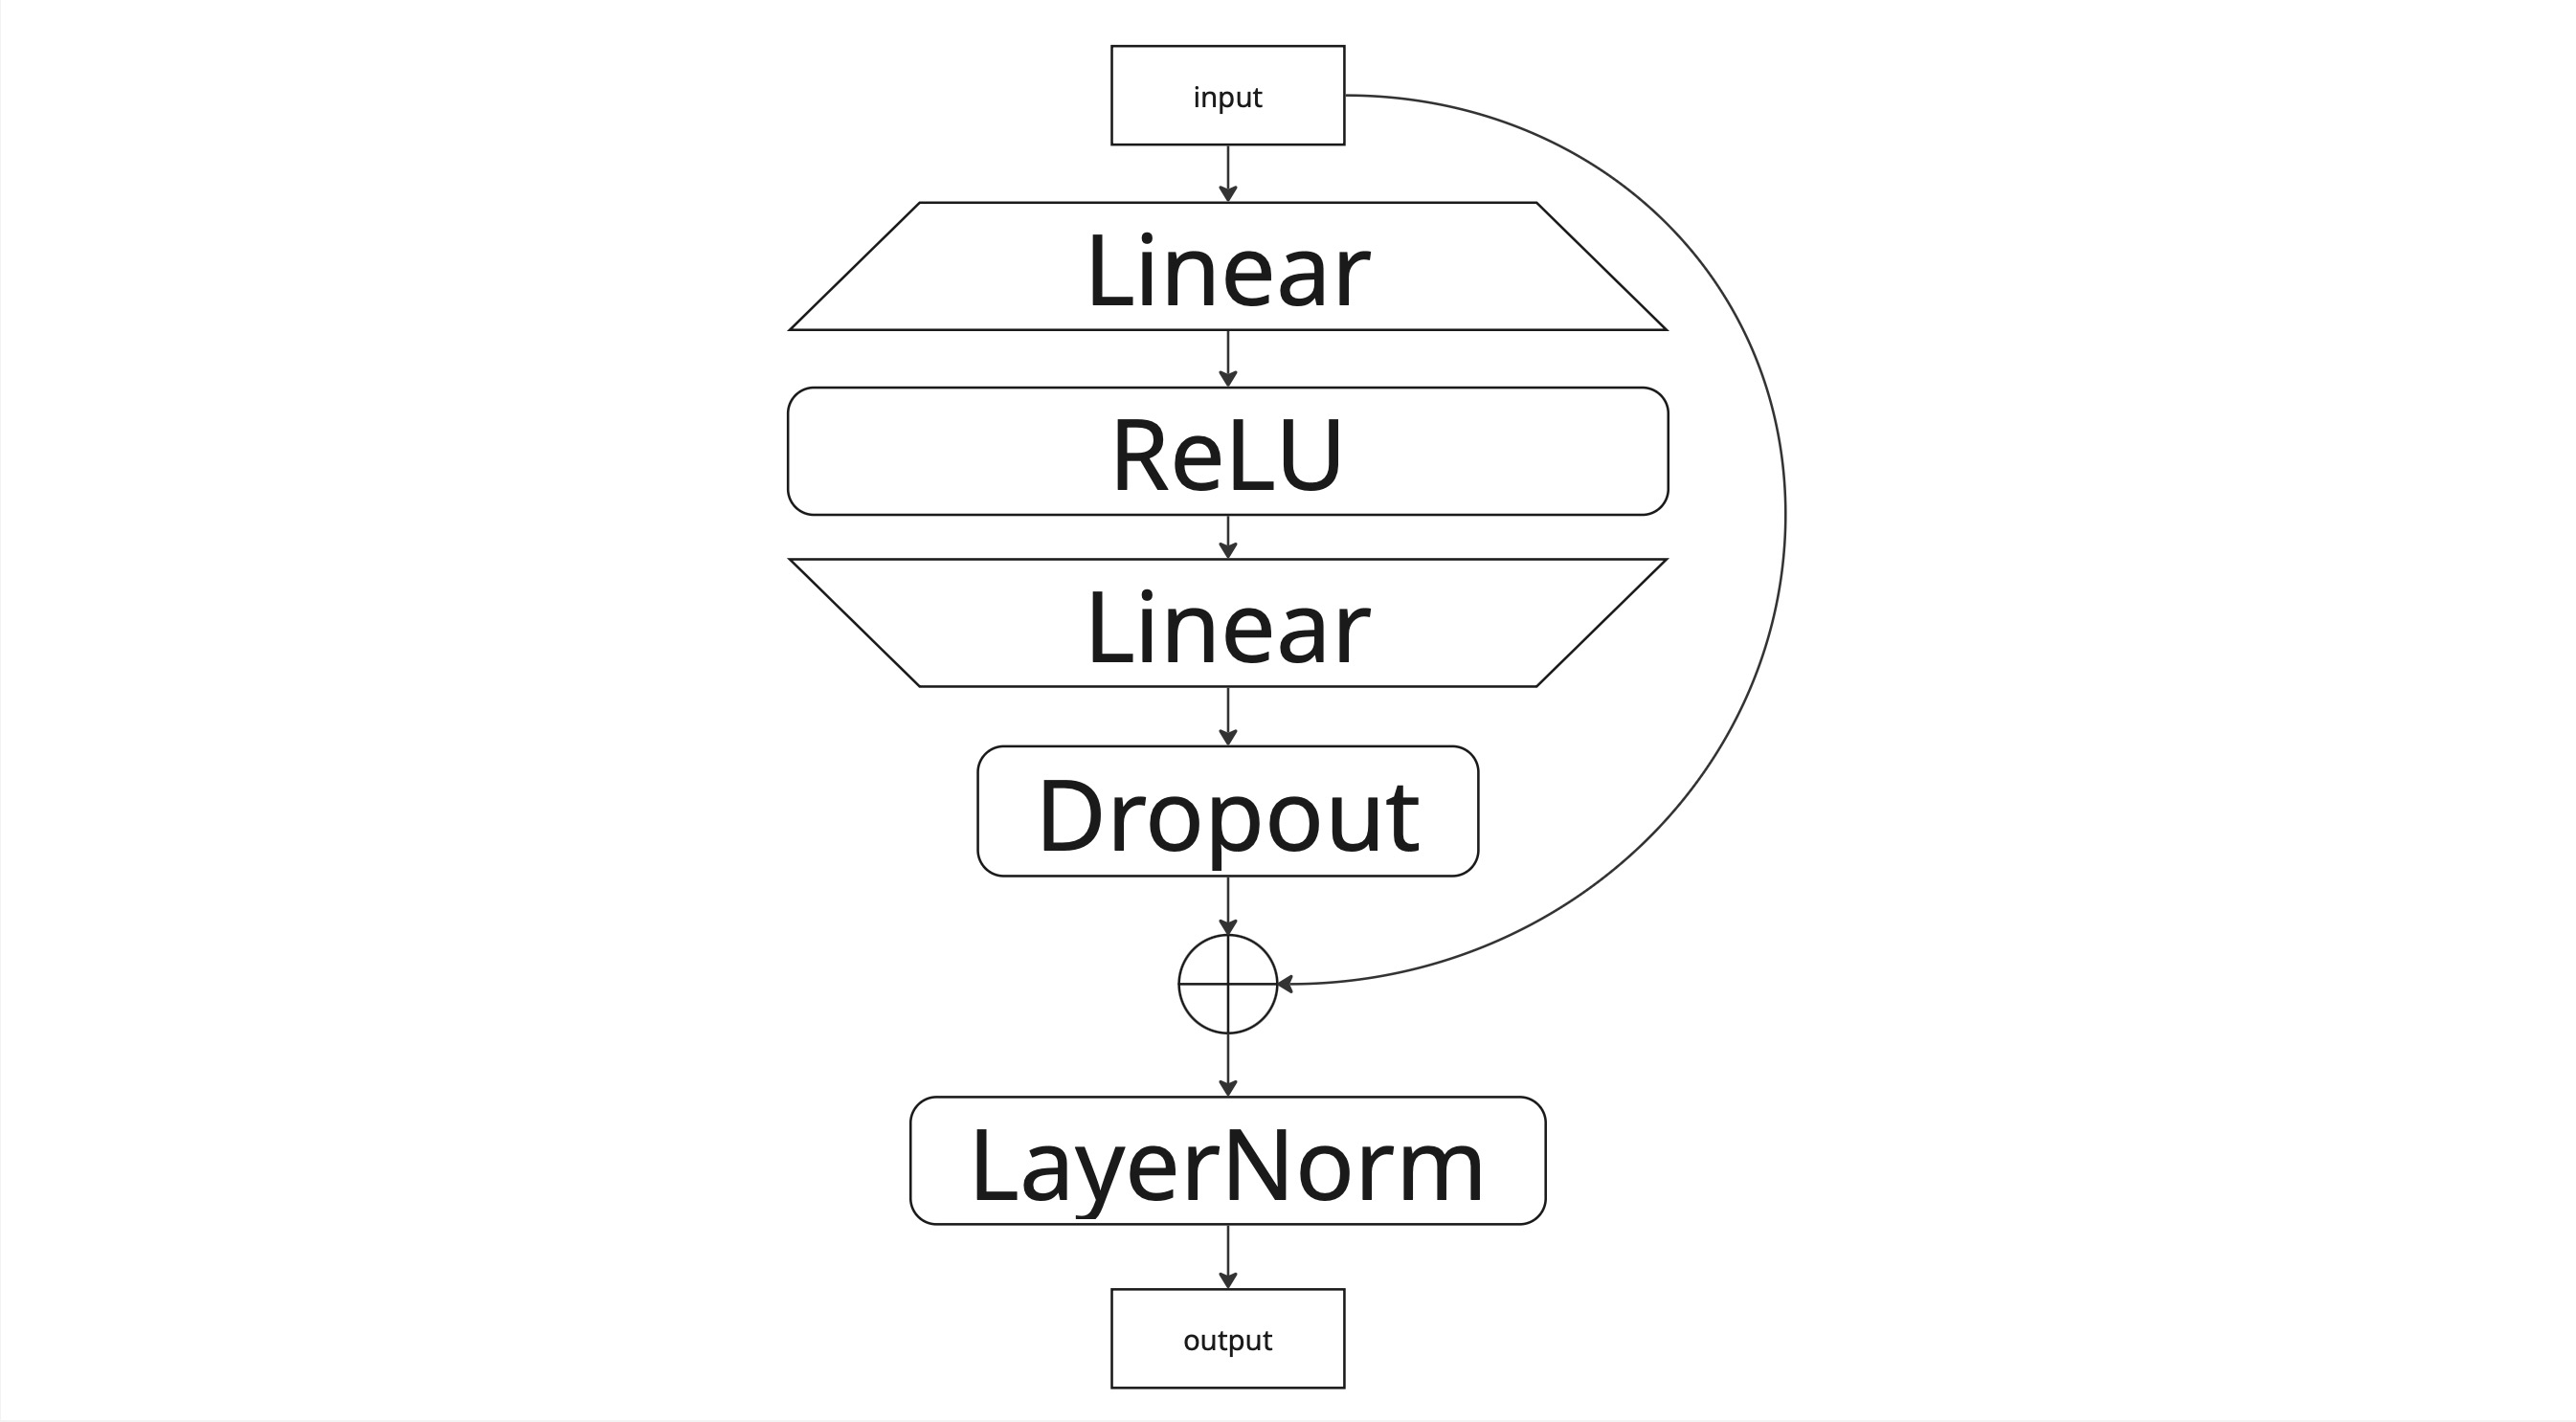

In [30]:
class MLPBlock(nn.Module):
    def __init__(self, dim, expand=4, dropout=0.0):
        super().__init__()
        self.mlp = nn.Sequential(
            #### ВАШ КОД ####
            nn.Linear(dim, dim * expand),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim * expand, dim),
            #### ВАШ КОД ####

        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return self.norm(x + self.mlp(x))

#### 2. `MLPActHead` — голова политики 2 балла

Эта сеть принимает **стекированное состояние** (вектор размерности `state_dim`) и предсказывает **действие** (вектор размерности `act_dim`).  
Особенность архитектуры — **многократное возвращение к исходному состоянию** на промежуточных этапах:

1. **Первый этап**:  
   - Состояние проецируется в скрытое пространство `hidden_dim` → `proj0`.  
   - Обрабатывается через `MLPBlock` → `block0`.

2. **Второй этап**:  
   - К текущему скрытому представлению **конкатенируется исходное состояние** (`[x, state]`).  
   - Результат проецируется в `hidden_dim` → `proj1`.  
   - Обрабатывается через `MLPBlock` → `block1`.

3. **Третий этап**:  
   - Снова конкатенируется исходное состояние → `[x, state]`.  
   - Проекция → `proj2`, затем `block2`.

4. **Финальный выход**:  
   - Линейная проекция `proj_end` преобразует скрытое представление в пространство действий.



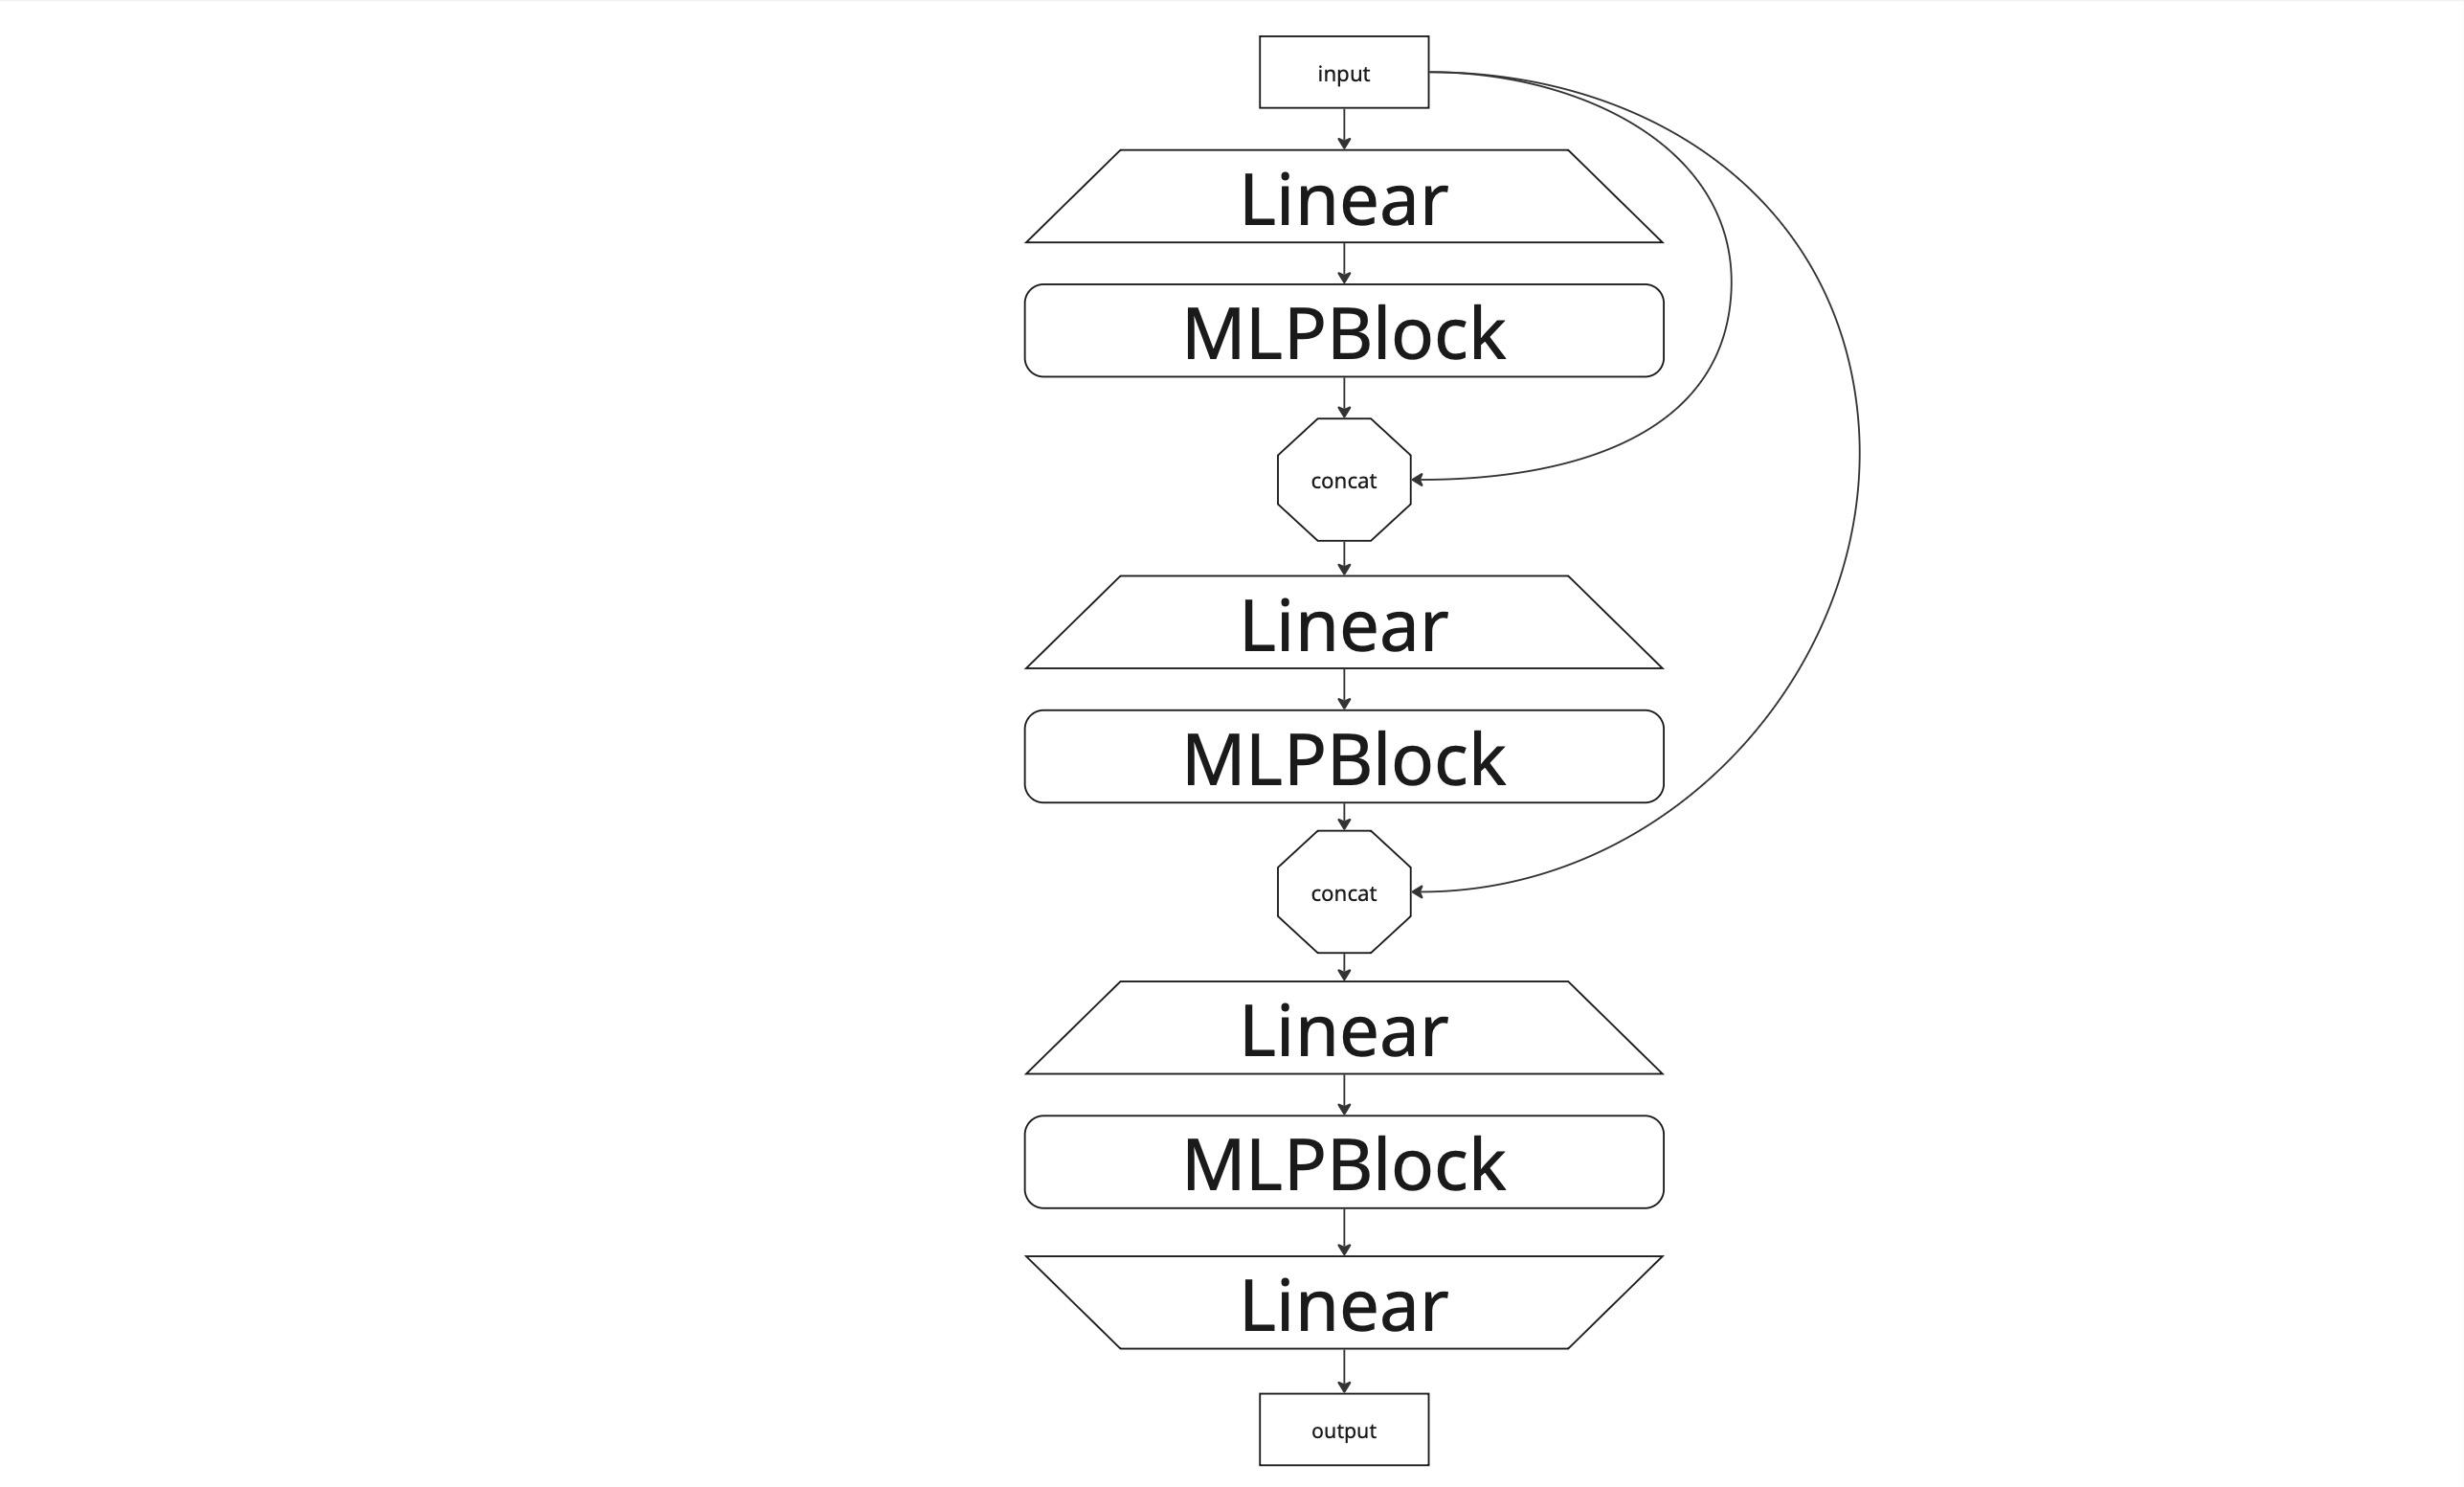

> 💡 **Зачем конкатенировать исходное состояние несколько раз?**  
> Это позволяет сети на каждом этапе «вспоминать» исходные признаки, не теряя контекст. Особенно полезно, когда `state_dim` велико, а промежуточные представления могут «забыть» важные детали. Такой приём используется в современных архитектурах (например, в ResNet с identity skip-connections или в некоторых transformer-based policy heads).

In [31]:
class MLPActHead(nn.Module):
    def __init__(self, act_dim, state_dim, hidden_dim, expand=4, dropout=0.0):
        super().__init__()
        #### ВАШ КОД ####
        self.proj0 = nn.Linear(state_dim, hidden_dim)
        self.block0 = MLPBlock(hidden_dim, expand, dropout)
        self.proj1 = nn.Linear(hidden_dim + state_dim, hidden_dim)
        self.block1 = MLPBlock(hidden_dim, expand, dropout)
        self.proj2 = nn.Linear(hidden_dim + state_dim, hidden_dim)
        self.block2 = MLPBlock(hidden_dim, expand, dropout)
        self.proj_end = nn.Linear(hidden_dim, act_dim)
    def forward(self, state):
        x = self.block0(self.proj0(state))
        x = torch.cat([x, state], dim=-1)
        x = self.block1(self.proj1(x))
        x = torch.cat([x, state], dim=-1)
        x = self.block2(self.proj2(x))
        return self.proj_end(x)
        #### ВАШ КОД ####

In [32]:
bc_actor = MLPActHead(dataset.action_dim, dataset.state_dim * frame_stack, 32).to(device)

In [33]:
import torchinfo

torchinfo.summary(
    bc_actor, input_size=[(1, dataset.state_dim * frame_stack)]
)

Layer (type:depth-idx)                   Output Shape              Param #
MLPActHead                               [1, 6]                    --
├─Linear: 1-1                            [1, 32]                   1,120
├─MLPBlock: 1-2                          [1, 32]                   --
│    └─Sequential: 2-1                   [1, 32]                   --
│    │    └─Linear: 3-1                  [1, 128]                  4,224
│    │    └─ReLU: 3-2                    [1, 128]                  --
│    │    └─Dropout: 3-3                 [1, 128]                  --
│    │    └─Linear: 3-4                  [1, 32]                   4,128
│    └─LayerNorm: 2-2                    [1, 32]                   64
├─Linear: 1-3                            [1, 32]                   2,144
├─MLPBlock: 1-4                          [1, 32]                   --
│    └─Sequential: 2-3                   [1, 32]                   --
│    │    └─Linear: 3-5                  [1, 128]                  4,224


## Обучение Behavioral Cloning (1 балл)

На этом этапе вы обучаете нейросеть **методом Behavioral Cloning (BC)** — простейшей формы imitation learning, при которой агент обучается **регрессии**: по входному состоянию предсказывать действие, которое совершил эксперт.

1. **Оптимизатор**  
   Используется `AdamW` с раздельной настройкой weight decay:
   - Для матриц (параметров размерности ≥2) — применяется регуляризация.
   - Для векторов (смещения, scale-параметры) — регуляризация отключена, чтобы не повредить адаптивные характеристики модели.

In [34]:
def get_optim_groups(model, weight_decay):
    return [
        # do not decay biases and single-column parameters (rmsnorm), those are usually scales
        {"params": (p for p in model.parameters() if p.dim() < 2), "weight_decay": 0.0},
        {
            "params": (p for p in model.parameters() if p.dim() >= 2),
            "weight_decay": weight_decay,
        },
    ]

learning_rate = 0.001

# init optimizer
optim = torch.optim.AdamW(
    params=get_optim_groups(bc_actor, 0.0),
    lr=learning_rate,
    fused=True,
)

2. **Планировщик скорости обучения** (learning rate scheduling)
   Реализован линейный **warmup + decay**:  
   - Сначала learning rate линейно растёт от 0 до максимума (в данном случае — сразу до максимума, так как `warmup_epochs = 0`),  
   - Затем линейно убывает до нуля к концу обучения.  
   Это стабилизирует ранние шаги обучения и улучшает сходимость.

In [35]:
import torch
import math
import functools

def _linear_decay_warmup(iteration, warmup_iterations, total_iterations):
    """
    Linear warmup from 0 --> 1.0, then linear decay to 0
    """
    if iteration < warmup_iterations:
        multiplier = iteration / warmup_iterations
    else:
        multiplier = 1.0 - ((iteration - warmup_iterations) / (total_iterations - warmup_iterations))
    return multiplier

def linear_annealing_with_warmup(optimizer, warmup_steps, total_steps):
    _decay_func = functools.partial(
        _linear_decay_warmup,
        warmup_iterations=warmup_steps,
        total_iterations=total_steps,
    )
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, _decay_func)
    return scheduler

In [36]:
num_epochs = 10
warmup_epochs = 0

total_updates = len(dataloader) * num_epochs
warmup_updates = len(dataloader) * warmup_epochs
scheduler = linear_annealing_with_warmup(optim, warmup_updates, total_updates)

3. **Функция потерь**  
   Используется **среднеквадратичная ошибка (MSE)** между предсказанным действием и действием эксперта:
   $$
   \mathcal{L} = \frac{1}{N} \sum_{i=1}^N \| a_{\text{pred}}^{(i)} - a_{\text{expert}}^{(i)} \|^2
   $$

In [37]:
import torch.nn.functional as F

for epoch in trange(num_epochs, desc="Epochs"):
    losses, n = 0, 0
    bc_actor.train()
    for batch in dataloader:

        states, target_action = [b.to(device) for b in batch]

        pred_action = bc_actor(states)
        loss = F.mse_loss(pred_action, target_action)

        losses += loss.item()
        n += batch_size

        optim.zero_grad(set_to_none=True)
        loss.backward()

        optim.step()
        scheduler.step()

    print(f"\n\nEpoch {epoch} latest batch loss:\n{losses / n}")

Epochs:  10%|█         | 1/10 [00:38<05:49, 38.82s/it]



Epoch 0 latest batch loss:
0.00874047861978761


Epochs:  20%|██        | 2/10 [01:16<05:05, 38.19s/it]



Epoch 1 latest batch loss:
0.0018190806608618004


Epochs:  30%|███       | 3/10 [01:54<04:26, 38.04s/it]

...



Epoch 7 latest batch loss:
0.0009933556815376506


Epochs:  90%|█████████ | 9/10 [05:47<00:38, 38.69s/it]



Epoch 8 latest batch loss:
0.0009398930220195325


Epochs: 100%|██████████| 10/10 [06:25<00:00, 38.54s/it]



Epoch 9 latest batch loss:
0.0008935264686006122


4. **Оценка качества**  
   После обучения агент тестируется на 50 эпизодах в среде `cheetah/run`.  
   Важно: при оценке используется **та же глубина frame stacking**, что и при обучении (`frame_stack=2`), иначе входы будут несовместимы!

In [38]:
@torch.no_grad()
def evaluate_actor(
    env,
    bc_actor: MLPActHead,
    num_episodes: int = 1,
    seed: int = 0,
) -> List[float | int]:
    returns = []
    for ep in trange(num_episodes, desc="Evaluating", leave=False):
        total_reward = 0.0
        obs, info = env.reset(seed=seed + ep)
        done = False
        while not done:
            obs_ = torch.tensor(obs.copy(), device=device)
            obs_ = obs_[None].contiguous()  # [1 dim]

            action = bc_actor(obs_)

            obs, reward, terminated, truncated, info = env.step(
                action.squeeze().cpu().numpy()
            )
            done = terminated or truncated
            total_reward += reward
        returns.append(total_reward)

    return np.array(returns)

> 💡 **Интерпретация результата**  
> Если вы видите низкую награду, это означает, что BC-агент **не смог обобщить** поведение эксперта.  
> Возможные причины:
> - недостаточно данных (попробуйте обучиться на 1000 траекториях, а не на 10),
> - несовпадение распределений (covariate shift): агент попадает в состояния, которых не было в экспертном датасете,
> - слишком агрессивное обучение (попробуйте уменьшить learning rate или добавить dropout).

> **Для получения 1 балла**:  
> - Корректно запустить обучение BC на вашем датасете,  
> - Продемонстрировать, что loss убывает,  
> - Получить **награду не ниже 700** при оценке на 50 эпизодах (это ~85% от экспертного результата).

In [39]:
env = make_env("cheetah", "run", frame_stack=frame_stack, flatten_frames=True)()
returns = evaluate_actor(env, bc_actor, 50, 0)

In [40]:
print(f"{np.mean(returns):.0f} +- {np.std(returns):.0f}")
print(f"{iqm(returns):.0f} +- {iqm_std(returns):.0f}")

841 +- 26
845 +- 7


## Анализ зависимости качества BC от размера датасета (5 баллов)

В этом задании вы исследуете, **как размер экспертного датасета влияет на качество обученной политики**. Это важный вопрос в imitation learning: слишком маленький датасет приводит к переобучению, а слишком большой — к высоким вычислительным затратам.

- Обучите BC-агентов на подмножествах одного и того же датасета, используя разное количество траекторий:  
  **`[2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]`**.
- Для каждого размера:
  1. Создайте `StackedDataset` с параметром `max_videos=N` (не нужно собирать отдельные HDF5-файлы!).
  2. Обучите новую сеть `MLPActHead` с нуля (важно: не дообучайте старую!).
  3. Оцените политику на **50 эпизодах** с фиксированным `seed=0`. <!-- If you are generating the solution, store the results of this experiment in a dict named bc_scaling_grid. -->
- В качестве метрики используйте **IQM (Interquartile Mean)** и **стандартное отклонение по IQM** (см. функции `iqm`, `iqm_std` из предыдущего раздела).

## Постройте графики:
  - **Ось X**: количество траекторий в датасете (логарифмический масштаб рекомендуется).
  - **Ось Y**: `IQM ± IQM_STD`,`MEAN ± STD`(2 графика) награды BC-агента: 2 кривые
    1. **In-distribution**: используйте те же сиды, что и в датасете (`seed=0, 1, ..., 49`).
    2. **Out-of-distribution**: используйте новые сиды, которых **нет в датасете** (`seed=5000, 5001, ..., 5049`).

    > 💡 **Зачем это нужно?**  
    > Экспертный датасет собран с `seed=0..999`. Если вы оцениваете BC на `seed=0..49`, агент может «вспомнить» поведение из датасета (особенно при малом числе траекторий). Оценка на новых сидах покажет **настоящую обобщающую способность**.

#### Советы:
- Используйте одинаковые гиперпараметры (learning rate, batch size, архитектуру) для всех запусков.
- Сохраняйте результаты в список/словарь, чтобы построить график в конце.


In [41]:
train_sizes = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
num_eval_episodes = 50
num_epochs = 10
learning_rate = 0.001
batch_size = 128
hidden_dim = 32

bc_dict= {
    'train_sizes': train_sizes,
    'in_dist_iqm': [], 'in_dist_iqm_std': [],
    'in_dist_mean': [], 'in_dist_std': [],
    'ood_iqm': [], 'ood_iqm_std': [],
    'ood_mean': [], 'ood_std': []}

eval_env = make_env("cheetah", "run", render_enabled=False, frame_stack=frame_stack)()

for n_traj in train_sizes:
    print(f"Training on {n_traj} trajectories")
    #первые n_traj траекторий
    dataset_sub = StackedDataset(dataset_path, frame_stack, device, max_videos=n_traj)
    dataloader_sub = DataLoader(dataset_sub, batch_size=batch_size, shuffle=True, drop_last=True)
    #новая модель
    bc_actor_sub = MLPActHead(dataset_sub.action_dim, dataset_sub.state_dim * frame_stack, hidden_dim).to(device)
    optim_sub = torch.optim.AdamW(get_optim_groups(bc_actor_sub, 0.0), lr=learning_rate, fused=True)
    total_updates = len(dataloader_sub) * num_epochs
    scheduler_sub = linear_annealing_with_warmup(optim_sub, 0, total_updates)

    #обучение
    bc_actor_sub.train()
    for epoch in trange(num_epochs, desc="Epochs", leave=False):
        for batch in dataloader_sub:
            states, target_action = [b.to(device) for b in batch]
            pred_action = bc_actor_sub(states)
            loss = F.mse_loss(pred_action, target_action)
            optim_sub.zero_grad(set_to_none=True)
            loss.backward()
            optim_sub.step()
            scheduler_sub.step()

    #In-distribution оценка
    bc_actor_sub.eval()
    in_dist_returns = evaluate_actor(eval_env, bc_actor_sub, num_eval_episodes, seed=0)
    bc_dict['in_dist_iqm'].append(iqm(in_dist_returns))
    bc_dict['in_dist_iqm_std'].append(iqm_std(in_dist_returns))
    bc_dict['in_dist_mean'].append(np.mean(in_dist_returns))
    bc_dict['in_dist_std'].append(np.std(in_dist_returns))

    #Out-of-distribution оценка
    ood_returns = evaluate_actor(eval_env, bc_actor_sub, num_eval_episodes, seed=5000)
    bc_dict['ood_iqm'].append(iqm(ood_returns))
    bc_dict['ood_iqm_std'].append(iqm_std(ood_returns))
    bc_dict['ood_mean'].append(np.mean(ood_returns))
    bc_dict['ood_std'].append(np.std(ood_returns))

    print(f"  In-Dist IQM: {bc_dict['in_dist_iqm'][-1]:.1f} ± {bc_dict['in_dist_iqm_std'][-1]:.1f}")
    print(f"  OOD IQM:     {bc_dict['ood_iqm'][-1]:.1f} ± {bc_dict['ood_iqm_std'][-1]:.1f}")

Training on 2 trajectories
Loaded 2 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 2.4 ± 0.1
  OOD IQM:     2.5 ± 0.1
Training on 4 trajectories
Loaded 4 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 84.6 ± 5.8
  OOD IQM:     83.1 ± 6.6
Training on 8 trajectories
Loaded 8 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 89.6 ± 21.5
  OOD IQM:     76.4 ± 19.6
Training on 16 trajectories
Loaded 16 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 127.0 ± 30.0
  OOD IQM:     126.7 ± 28.1
Training on 32 trajectories
Loaded 32 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


...

  In-Dist IQM: 285.5 ± 93.8
  OOD IQM:     364.2 ± 85.5
Training on 128 trajectories
Loaded 128 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 502.6 ± 195.6
  OOD IQM:     684.0 ± 99.2
Training on 256 trajectories
Loaded 256 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 832.5 ± 8.8
  OOD IQM:     834.6 ± 8.9
Training on 512 trajectories
Loaded 512 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 842.8 ± 6.3
  OOD IQM:     841.2 ± 7.1
Training on 1024 trajectories
Loaded 1024 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5


  In-Dist IQM: 844.4 ± 4.4
  OOD IQM:     844.3 ± 8.2


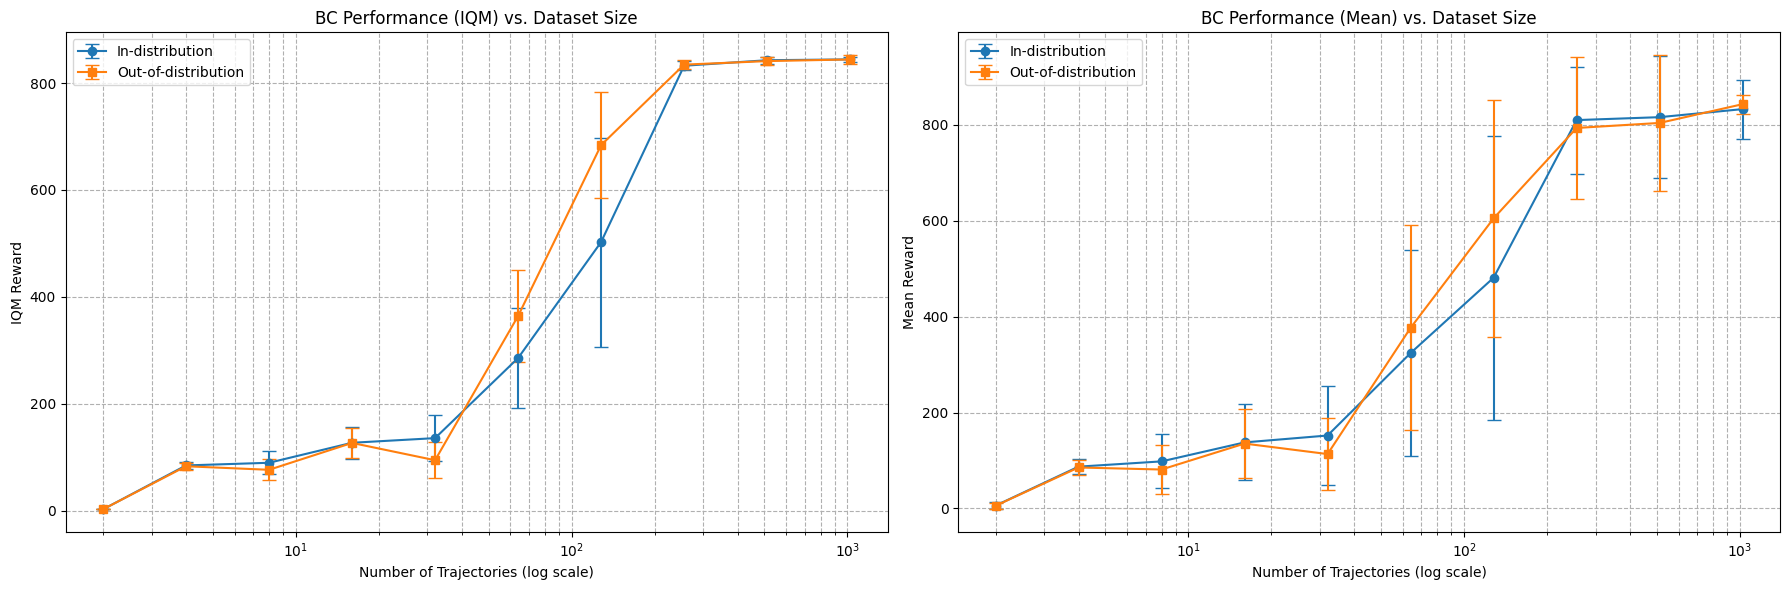

In [42]:
import warnings
warnings.filterwarnings("ignore", message=".*is deprecated.*")
warnings.filterwarnings("ignore", module="matplotlib.*")
warnings.filterwarnings("ignore", module="pyparsing.*")
import matplotlib.pyplot as plt
#графики
#IQM
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].errorbar(train_sizes, bc_dict['in_dist_iqm'], yerr=bc_dict['in_dist_iqm_std'],
                 fmt='-o', label='In-distribution', capsize=5)
axes[0].errorbar(train_sizes, bc_dict['ood_iqm'], yerr=bc_dict['ood_iqm_std'],
                 fmt='-s', label='Out-of-distribution', capsize=5)
axes[0].set_xscale('log')
axes[0].set_xlabel('Number of Trajectories (log scale)')
axes[0].set_ylabel('IQM Reward')
axes[0].set_title('BC Performance (IQM) vs. Dataset Size')
axes[0].legend()
axes[0].grid(True, which="both", ls="--")

#Mean
axes[1].errorbar(train_sizes, bc_dict['in_dist_mean'], yerr=bc_dict['in_dist_std'],
                 fmt='-o', label='In-distribution', capsize=5)
axes[1].errorbar(train_sizes, bc_dict['ood_mean'], yerr=bc_dict['ood_std'],
                 fmt='-s', label='Out-of-distribution', capsize=5)
axes[1].set_xscale('log')
axes[1].set_xlabel('Number of Trajectories (log scale)')
axes[1].set_ylabel('Mean Reward')
axes[1].set_title('BC Performance (Mean) vs. Dataset Size')
axes[1].legend()
axes[1].grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()

## Dagger  (5 баллов)

**Behavioral Cloning (BC)** страдает от так называемого **covariate shift**: обученная политика может отклониться от экспертной траектории и попасть в состояния, которых не было в датасете. В таких состояниях она ведёт себя непредсказуемо, что усугубляет ошибку — и так далее.

Алгоритм **DAgger (Dataset Aggregation)** решает эту проблему **итеративно**:
1. На каждой итерации агент собирает траектории, используя **текущую политику**.
2. Для каждого посещённого состояния запрашивается **действие от эксперта**.
3. Пары `(состояние, экспертное_действие)` добавляются в обучающий датасет.
4. Политика переобучается на расширенном датасете.

#### 🔧 Вспомогательные компоненты

Чтобы упростить реализацию, мы рекомендуем использовать:

1. **`UpdateDataset`** — наследник `StackedDataset`, который поддерживает метод `.update(new_states, new_actions)`.  
   → **Важно**: передавайте **исходные состояния** (`obs` размерности 17), **НЕ стекированные**!  
   → Датасет сам позаботится о frame stacking при обучении.

In [43]:
class UpdateDataset(StackedDataset):

    def update(self, new_states, new_actions):
        state_dim = self.states[0].shape[-1]
        assert state_dim == self.state_dim, "Your state_dim in new_states != state_dim in dataset. Check that you do NOT collect frame_stacked states."

        new_states = [torch.tensor(s, device=self.device) for s in new_states]
        new_actions = [torch.tensor(a, device=self.device) for a in new_actions]

        self.states.extend(new_states)
        self.actions.extend(new_actions)

        self.traj_len = self.states[0].shape[0]

In [44]:
# dataset = UpdateDataset(dataset_path, frame_stack, device, max_videos=)

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
)

2. **`log_actor_trajectories_with_expert_actions(...)`** — функция, которая:
   - Собирает траектории с помощью **вашего BC-агента**,
   - Для **каждого состояния** запрашивает **действие у эксперта**,
   - Возвращает списки: `states` (исходные, не стекированные! (без frame-stack)), `actions` (экспертные), и `returns`.

In [45]:
@torch.no_grad()
def log_actor_trajectories_with_expert_actions(
    env,
    expert: Agent,
    bc_actor: MLPActHead,
    num_episodes: int = 1,
    seed: int = 0,
) -> List[float | int]:
    states_arr = []
    actions_arr = []
    returns = []
    for ep in trange(num_episodes, desc="Evaluating", leave=False):
        states = []
        actions = []
        total_reward = 0.0
        obs, info = env.reset(seed=seed + ep)
        done = False
        while not done:

            #### ВАШ КОД ####
            current_obs = obs[-17:]
            states.append(current_obs.copy())
            expert_action = expert.act_numpy(current_obs, greedy=False)
            actions.append(expert_action)
            obs_tensor = torch.tensor(obs, device=device)[None]
            bc_action = bc_actor(obs_tensor).squeeze().cpu().numpy()
            obs, reward, terminated, truncated, _ = env.step(bc_action)
            total_reward += reward
            done = terminated or truncated
            #### ВАШ КОД ####

        returns.append(total_reward)
        states_arr.append(np.array(states))
        actions_arr.append(np.array(actions))

    return states_arr, actions_arr, np.array(returns)

In [46]:
states, actions, returns = log_actor_trajectories_with_expert_actions(env, expert, bc_actor, num_episodes=2, seed=123)

In [47]:
#отладка
debug_dataset = UpdateDataset(dataset_path, frame_stack=frame_stack, device=device, max_videos=2)
print(f"Initial: {len(debug_dataset.states)} trajectories, traj_len={debug_dataset.traj_len}")
states, actions, returns = log_actor_trajectories_with_expert_actions(
    env, expert, bc_actor, num_episodes=2, seed=123)

print("\nФормы до обновления")
print(f"New states[0].shape  = {states[0].shape}   (ожидается (T, 17))")
print(f"New actions[0].shape = {actions[0].shape}   (ожидается (T, 6))")
print(f"New returns          = {returns}")
print(f"dataset.state_dim    = {debug_dataset.state_dim}   (должно быть 17)")
assert states[0].shape[-1] == debug_dataset.state_dim, \
    f"state_dim mismatch: {states[0].shape[-1]} != {debug_dataset.state_dim}"

#Обновляем датасет
debug_dataset.update(states, actions)
print("\nПосле обновления")
print(f"Trajectories in dataset: {len(debug_dataset.states)}   (ожидается 4)")
print(f"Traj lengths: {[s.shape[0] for s in debug_dataset.states]}")


obs, act = debug_dataset[0]
print(f"\n__getitem__(0):")
print(f"  obs.shape = {obs.shape}   (ожидается ({debug_dataset.state_dim * frame_stack},) = ({17*frame_stack},))")
print(f"  act.shape = {act.shape}   (ожидается ({debug_dataset.action_dim},))")

assert obs.shape[0] == debug_dataset.state_dim * frame_stack, \
    f"Stacked obs dim mismatch: {obs.shape[0]} != {debug_dataset.state_dim * frame_stack}"

#сравниваем последние 2 траектории с собранными
last_two_states = debug_dataset.states[-2:]
for i, (new_state, last_state) in enumerate(zip(states, last_two_states)):
    match = torch.allclose(
        torch.tensor(new_state, dtype=torch.float32, device=device),
        last_state.float(),
        atol=1e-5)
    print(f" Traj new[-{2-i}] == dataset.states[{len(debug_dataset.states)-2+i}]: {match}")
    assert match, "Данные не совпадают!"

#Проверяем, что DataLoader работает с обновлённым датасетом
debug_loader = DataLoader(debug_dataset, batch_size=16, shuffle=True, drop_last=False)
batch_obs, batch_act = next(iter(debug_loader))
print(f"\nDataLoader batch:")
print(f"  obs.shape = {batch_obs.shape}   (ожидается (16, {17*frame_stack}))")
print(f"  act.shape = {batch_act.shape}   (ожидается (16, {debug_dataset.action_dim}))")
assert batch_obs.shape == (16, debug_dataset.state_dim * frame_stack)
assert batch_act.shape == (16, debug_dataset.action_dim)

print("\nВсе проверки пройдены!")

Loaded 2 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5
Initial: 2 trajectories, traj_len=1000



Формы до обновления
New states[0].shape  = (1000, 17)   (ожидается (T, 17))
New actions[0].shape = (1000, 6)   (ожидается (T, 6))
New returns          = [853.08935495 853.85181817]
dataset.state_dim    = 17   (должно быть 17)

После обновления
Trajectories in dataset: 4   (ожидается 4)
Traj lengths: [1000, 1000, 1000, 1000]

__getitem__(0):
  obs.shape = torch.Size([34])   (ожидается (34,) = (34,))
  act.shape = torch.Size([6])   (ожидается (6,))
 Traj new[-2] == dataset.states[2]: True
 Traj new[-1] == dataset.states[3]: True

DataLoader batch:
  obs.shape = torch.Size([16, 34])   (ожидается (16, 34))
  act.shape = torch.Size([16, 6])   (ожидается (16, 6))

Все проверки пройдены!


#### Требования к реализации

Выполните **5-10 итераций DAgger**:

- **Инициализация**:  
  Инициализируйте `UpdateDataset` с `max_videos=100` (или 50–300) — это ваш стартовый датасет от эксперта.

- **На каждой итерации**:
  1. Создайте **новую сеть** `MLPActHead` (обучайте **с нуля**, не дообучайте!).
  2. Обучите её на **текущем датасете** (используйте тот же цикл обучения, что и в BC).
  3. Соберите **10-20 новых траекторий** с помощью `log_actor_trajectories_with_expert_actions(...)`.
  4. Обновите датасет: `dataset.update(states, actions)`.
  5. **Оцените** политику: выведите `IQM ± IQM_STD`,`MEAN ± STD` по возвращённым `returns`.

- **В конце**: постройте график `итерация → IQM`.

#### Что нужно для 5 баллов

- Корректная реализация цикла DAgger (10 итераций),
- Использование **экспертных действий** для состояний, порождённых **текущей политикой**,
- **Обучение BC-агента с нуля** на каждой итерации,
- Вывод **IQM и IQM_STD** после каждой итерации,
- **График** зависимости IQM от номера итерации,
- Интерпретация результатов: краткий **комментарий** (2–3 предложения) — *сравнение DAgger и BC* с учётом того, сколько экспертных данных использовал каждый метод. <!-- Обязательно используйте выражение «петля экспертной перемаркировки». -->

#### Пример структуры кода

```python
# Инициализация
env = make_env("cheetah", "run", render_enabled=False, frame_stack=frame_stack)()
dataset = UpdateDataset(dataset_path, frame_stack=frame_stack, device=device, max_videos=100)
dagger_scores = ... # логгирование метрик для графика

for iteration in range(10):
    # 1. Создать и обучить новую политику
    bc_actor = MLPActHead(...).to(device)
    # ... (цикл обучения)

    # 2. Собрать новые данные с помощью текущей политики + эксперта
    states, actions, returns = log_actor_trajectories_with_expert_actions(
        env, expert, bc_actor, num_episodes=10, seed=5000 + iteration * 10
    )

    # 3. Обновить датасет
    dataset.update(states, actions)

    # 4. Вывести результат
    print(f"Iteration {iteration} → IQM: {iqm(returns):.1f} ± {iqm_std(returns):.1f}")
```

In [48]:
num_dagger_iterations = 10
initial_dataset_size = 100
new_trajectories_per_iter = 10

env = make_env("cheetah", "run", render_enabled=False, frame_stack=frame_stack)()
dataset = UpdateDataset(dataset_path, frame_stack=frame_stack, device=device, max_videos=initial_dataset_size)

dagger_scores = {
    'iteration': [], 'iqm': [], 'iqm_std': [], 'mean': [], 'std': []}
for iteration in range(num_dagger_iterations):
    print(f"DAgger Iteration {iteration + 1}/{num_dagger_iterations} (dataset: {len(dataset.states)} traj)")
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)
    bc_actor = MLPActHead(dataset.action_dim, dataset.state_dim * frame_stack, hidden_dim).to(device)
    optim = torch.optim.AdamW(get_optim_groups(bc_actor, 0.0), lr=learning_rate, fused=True)
    scheduler = linear_annealing_with_warmup(optim, 0, len(dataloader) * num_epochs)

    bc_actor.train()
    for epoch in trange(num_epochs, desc="Training", leave=False):
        for batch in dataloader:
            states_b, target_action_b = [b.to(device) for b in batch]
            pred_action_b = bc_actor(states_b)
            loss = F.mse_loss(pred_action_b, target_action_b)
            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()
            scheduler.step()
    bc_actor.eval()
    states, actions, returns = log_actor_trajectories_with_expert_actions(
        env, expert, bc_actor, num_episodes=new_trajectories_per_iter,
        seed=5000 + iteration * new_trajectories_per_iter)
    dataset.update(states, actions)

    current_iqm = iqm(returns)
    current_iqm_std = iqm_std(returns)
    current_mean = np.mean(returns)
    current_std = np.std(returns)

    dagger_scores['iteration'].append(iteration + 1)
    dagger_scores['iqm'].append(current_iqm)
    dagger_scores['iqm_std'].append(current_iqm_std)
    dagger_scores['mean'].append(current_mean)
    dagger_scores['std'].append(current_std)

    print(f" Iteration {iteration + 1}  IQM: {current_iqm:.1f} ± {current_iqm_std:.1f}, Mean: {current_mean:.1f} ± {current_std:.1f}")


Loaded 100 trajectories from /content/drive/MyDrive/HW3/bc_cheetah_run_1k.hdf5
DAgger Iteration 1/10 (dataset: 100 traj)


 Iteration 1  IQM: 459.6 ± 133.5, Mean: 482.0 ± 257.2
DAgger Iteration 2/10 (dataset: 110 traj)


 Iteration 2  IQM: 820.4 ± 6.4, Mean: 776.3 ± 87.5
DAgger Iteration 3/10 (dataset: 120 traj)


 Iteration 3  IQM: 804.7 ± 15.8, Mean: 677.5 ± 230.1
DAgger Iteration 4/10 (dataset: 130 traj)


 Iteration 4  IQM: 843.5 ± 14.8, Mean: 839.2 ± 29.5
DAgger Iteration 5/10 (dataset: 140 traj)


...

 Iteration 6  IQM: 838.3 ± 13.7, Mean: 833.3 ± 22.1
DAgger Iteration 7/10 (dataset: 160 traj)


 Iteration 7  IQM: 846.4 ± 2.0, Mean: 841.2 ± 15.9
DAgger Iteration 8/10 (dataset: 170 traj)


 Iteration 8  IQM: 841.8 ± 6.6, Mean: 804.3 ± 102.1
DAgger Iteration 9/10 (dataset: 180 traj)


 Iteration 9  IQM: 842.5 ± 8.7, Mean: 810.5 ± 76.9
DAgger Iteration 10/10 (dataset: 190 traj)


 Iteration 10  IQM: 839.0 ± 9.0, Mean: 786.8 ± 140.0


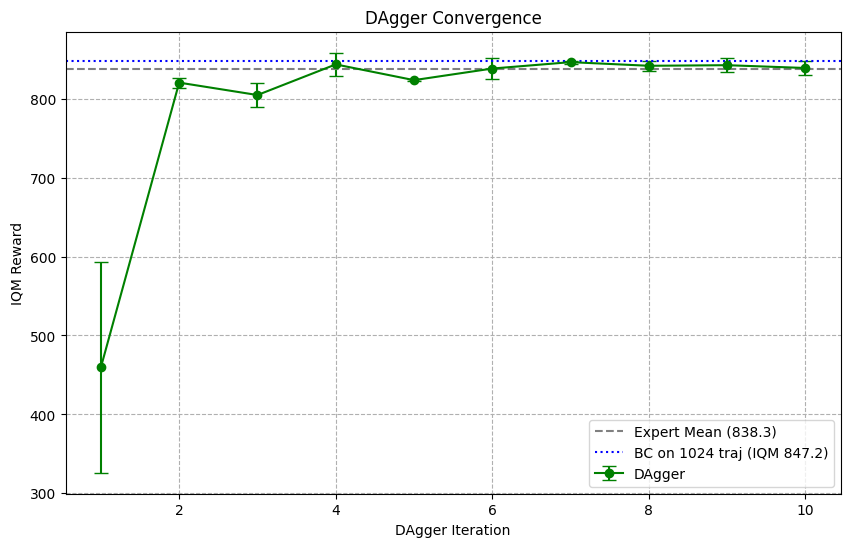

In [49]:

plt.figure(figsize=(10, 6))
plt.errorbar(dagger_scores['iteration'], dagger_scores['iqm'], yerr=dagger_scores['iqm_std'],
             fmt='-o', capsize=5, color='green', label='DAgger')
plt.axhline(y=838.3, color='gray', linestyle='--', label='Expert Mean (838.3)')
plt.axhline(y=847.2, color='blue', linestyle=':', label='BC on 1024 traj (IQM 847.2)')
plt.xlabel("DAgger Iteration")
plt.ylabel("IQM Reward")
plt.title("DAgger Convergence")
plt.legend()
plt.grid(True, ls="--")
plt.show()

**Выводы**

Dagger демонстрирует устойчивый рост IQM от итерации к итерации. В отличие от ВС ему необходимо меньше данных для получения большей награды. DAgger достигает качества 840+ за гораздо меньшее число траекторий, в то время как классическому BC для такого же уровня IQM требуется не менее 256–512 траекторий